# Adım 5: Bulanık Mantık Kapısı (Konsey toplansın mı?)

Her vaka için **0-100 arası bir "konsey gerekliliği" puanı** üretilir. Puan eşiği geçen vakalar konseye (şimdilik: uzmana) gider; diğerlerinde CNN'in kararı tanı önerisi olarak verilir.

**Neden bulanık mantık?** Klinik sezgi keskin eşiklerle değil, derecelerle düşünür. "Güven %79 ise konsey, %81 ise değil" demek yerine, "güven *düşükçe* ve arşiv *pek* desteklemiyorsa konsey toplansın" gibi kurallar yazarız. Kurallar Türkçe okunabilir; her kararın **hangi kuralla** verildiği gösterilebilir.

**Girdiler (hepsi önceki adımlarda üretildi, etiket bilgisi kullanılmaz):**
| Girdi | Tanım | Kaynak |
|---|---|---|
| Güven | Kalibre CNN olasılığının CNN'in kendi kararına (klinik τ) verdiği değer | Adım 3 |
| Uyum | Arşivin CNN'in kararına verdiği olasılık (benzer vakalar CNN'i destekliyor mu?) | Adım 4 |
| Risk | Kötü huylu sınıfların (melanom, BCC, aktinik keratoz) olasılığı; CNN ve arşivin ortalaması | Adım 3 + 4 |
| Yaş | Hasta yaşı; bilinmiyorsa nötr | Meta veri |

**Dilsel değerler:** Güven, uyum ve risk için *düşük / orta / yüksek* kümeleri, girdinin **doğrulama kümesindeki dağılımına** göre kurulur (%5, %50 ve %95 yüzdelikleri). Tam üyelik yalnızca uçlarda (en alt ve en üst %5) olduğu için puan kademeli değişir ve vakalar sıralanabilir. Bu yalnızca girdilerin dağılımına bakar, doğru tanıya bakmaz. Yaş için klinik sınırlar kullanılır (35 yaş altı genç, 50 üstü ileri).

**Önceden yazılan kurallar:**
1. Üyelik fonksiyonları ve 12 kural, sonuçlara bakılmadan sabitlendi.
2. Tek ayar **eşiktir**: doğrulamada vakaların %20'sini konseye gönderecek şekilde seçilir (Adım 3 ve 4 ile aynı bütçe). Eşik teste aynen taşınır.
3. Bulanık kapı, testte aynı sayıda vakayı uzmana gönderen iki temel çizgiyle karşılaştırılır: *yalnız güven* (Adım 3) ve *güven + uyumsuzluk* (Adım 4). Bütün sonuçlar raporlanır.

**Çalışma zamanı:** GPU gerekmez (CPU yeterli). Süre birkaç dakika.

## 1. Ortam ve veriler

In [1]:
!pip -q install scikit-fuzzy
import os, sys, json, importlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

KONSEY_BUTCESI = 0.20      # doğrulamada konseye gidecek vaka oranı (eşik buna göre seçilir)
TOHUM = 42
ON = '05'
rng = np.random.default_rng(TOHUM)
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')
for d in ['src', 'bulanik']:
    os.makedirs(f'{PROJE}/{d}', exist_ok=True)

with open(f'{PROJE}/results/03v2_son_cnn.json', encoding='utf-8') as f:
    SON_CNN = json.load(f)
with open(f'{PROJE}/rag/04_arsiv_ayarlari.json', encoding='utf-8') as f:
    ARSIV = json.load(f)
SINIFLAR = SON_CNN['siniflar']
MEL, NV = SINIFLAR.index('mel'), SINIFLAR.index('nv')
KOTU_HUYLU = [SINIFLAR.index(s) for s in ['mel', 'bcc', 'akiec']]
LOG_ONCEL = np.array(SON_CNN['log_oncel'])

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
SINIF_NO = {s: i for i, s in enumerate(SINIFLAR)}
KUME = {k: meta[meta['split'] == k].reset_index(drop=True) for k in ['dogrulama', 'test']}
Y = {k: df['dx'].map(SINIF_NO).values for k, df in KUME.items()}

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

LOGIT = {k: np.load(f'{PROJE}/models/son_cnn_{k}_logit.npy') for k in KUME}
P_CNN = {k: softmax(z / SON_CNN['T']) for k, z in LOGIT.items()}
KARAR = {k: (z - SON_CNN['tau_klinik'] * LOG_ONCEL).argmax(1) for k, z in LOGIT.items()}
P_ARSIV = {k: np.load(f'{PROJE}/rag/arsiv_olasilik_{k}.npy') for k in KUME}
for k in KUME:
    assert len(LOGIT[k]) == len(P_ARSIV[k]) == len(KUME[k]), f'{k}: dosya boyutları tutmuyor'
print({k: len(v) for k, v in KUME.items()}, '| son CNN:', SON_CNN['aday'], '| arşiv: k =', ARSIV['k'], ARSIV['oy'], 'oy')

Mounted at /content/drive
{'dogrulama': 1464, 'test': 1497} | son CNN: Topluluk + TTA | arşiv: k = 50 dengeli oy


## 2. Bulanık kapı modülü
Kod, Drive'da `src/bulanik_kapi.py` dosyasına yazılır ve oradan içe aktarılır. Sonraki adımlar ve web arayüzü aynı dosyayı kullanacak. GitHub'daki `src/` klasörüne de bu dosya konacak.

**Çıkarım (Mamdani):** VE = min, VEYA = max, DEĞİL = 1 − µ. Her kuralın gücü kadar çıkış kümesi kırpılır, kırpılan kümeler birleştirilir (max) ve ağırlık merkezi alınarak tek bir puana çevrilir.

In [2]:
%%writefile /content/drive/MyDrive/bitirme/src/bulanik_kapi.py
"""Bulanık mantık kapısı (Mamdani): CNN güveni, CNN-arşiv uyumu, klinik risk ve yaş -> konsey gerekliliği (0-100).

VE = min, VEYA = max, DEĞİL = 1 - µ; kural çıkışları min ile kırpılır, max ile birleştirilir,
ağırlık merkezi (centroid) ile durulaştırılır. Bütün işlemler numpy ile vektörel yapılır.
"""
import numpy as np

CIKIS_EVRENI = np.linspace(0, 100, 201)


def yamuk(x, a, b, c, d):
    """Yamuk üyelik fonksiyonu (a<=b<=c<=d). a==b sol omuz, c==d sağ omuz demektir."""
    x = np.asarray(x, dtype=float)
    y = np.where((x >= b) & (x <= c), 1.0, 0.0)
    if b > a:
        y = np.where((x > a) & (x < b), (x - a) / (b - a), y)
    if d > c:
        y = np.where((x > c) & (x < d), (d - x) / (d - c), y)
    return y


def uc_kume(q05, q50, q95, alt=0.0, ust=1.0):
    """Düşük / orta / yüksek kümeleri, girdinin doğrulama dağılımındaki %5, %50, %95 yüzdeliklerine göre.
    Tam üyelik yalnızca dağılımın uçlarında (en alt / en üst %5) olur; böylece puan kademeli değişir."""
    return {'dusuk': (alt, alt, q05, q50), 'orta': (q05, q50, q50, q95), 'yuksek': (q50, q95, ust, ust)}


YAS_KUMELERI = {'genc': (0, 0, 35, 50), 'ileri': (35, 50, 150, 150)}     # yaş bilinmiyorsa ikisi de 0,5
CIKIS_KUMELERI = {'dusuk': (0, 0, 0, 50), 'orta': (25, 50, 50, 75), 'yuksek': (50, 100, 100, 100)}


def ve(*a):
    return np.minimum.reduce(a)


def veya(*a):
    return np.maximum.reduce(a)


def degil(a):
    return 1.0 - a


# (ad, Türkçe kural, öncül fonksiyonu, çıkış kümesi)
KURALLAR = [
    ('K1', 'güven DÜŞÜK ise konsey YÜKSEK', lambda m: m['guven']['dusuk'], 'yuksek'),
    ('K2', 'uyum DÜŞÜK ise konsey YÜKSEK', lambda m: m['uyum']['dusuk'], 'yuksek'),
    ('K3', 'güven YÜKSEK ve uyum YÜKSEK ve risk DÜŞÜK ise konsey DÜŞÜK',
     lambda m: ve(m['guven']['yuksek'], m['uyum']['yuksek'], m['risk']['dusuk']), 'dusuk'),
    ('K4', 'güven YÜKSEK ve uyum YÜKSEK ve risk ORTA ise konsey DÜŞÜK',
     lambda m: ve(m['guven']['yuksek'], m['uyum']['yuksek'], m['risk']['orta']), 'dusuk'),
    ('K5', 'güven YÜKSEK ve uyum YÜKSEK ve risk YÜKSEK ise konsey ORTA',
     lambda m: ve(m['guven']['yuksek'], m['uyum']['yuksek'], m['risk']['yuksek']), 'orta'),
    ('K6', 'güven ORTA ve uyum YÜKSEK ve risk DÜŞÜK ise konsey DÜŞÜK',
     lambda m: ve(m['guven']['orta'], m['uyum']['yuksek'], m['risk']['dusuk']), 'dusuk'),
    ('K7', 'güven ORTA ve uyum YÜKSEK ve risk (ORTA veya YÜKSEK) ise konsey ORTA',
     lambda m: ve(m['guven']['orta'], m['uyum']['yuksek'], veya(m['risk']['orta'], m['risk']['yuksek'])), 'orta'),
    ('K8', 'güven YÜKSEK ve uyum ORTA ve risk DÜŞÜK ise konsey DÜŞÜK',
     lambda m: ve(m['guven']['yuksek'], m['uyum']['orta'], m['risk']['dusuk']), 'dusuk'),
    ('K9', 'güven YÜKSEK ve uyum ORTA ve risk (ORTA veya YÜKSEK) ise konsey ORTA',
     lambda m: ve(m['guven']['yuksek'], m['uyum']['orta'], veya(m['risk']['orta'], m['risk']['yuksek'])), 'orta'),
    ('K10', 'güven ORTA ve uyum ORTA ve risk DÜŞÜK ise konsey ORTA',
     lambda m: ve(m['guven']['orta'], m['uyum']['orta'], m['risk']['dusuk']), 'orta'),
    ('K11', 'güven ORTA ve uyum ORTA ve risk (ORTA veya YÜKSEK) ise konsey YÜKSEK',
     lambda m: ve(m['guven']['orta'], m['uyum']['orta'], veya(m['risk']['orta'], m['risk']['yuksek'])), 'yuksek'),
    ('K12', 'yaş İLERİ ve risk YÜKSEK ve DEĞİL(güven YÜKSEK ve uyum YÜKSEK) ise konsey YÜKSEK',
     lambda m: ve(m['yas']['ileri'], m['risk']['yuksek'], degil(ve(m['guven']['yuksek'], m['uyum']['yuksek']))), 'yuksek'),
]


class BulanikKapi:
    def __init__(self, yuzdelikler, kurallar=None):
        """yuzdelikler: {'guven': (q05, q50, q95), 'uyum': (...), 'risk': (...)}; kurallar: kullanılacak kural adları."""
        self.yuzdelikler = {k: tuple(float(v) for v in d) for k, d in yuzdelikler.items()}
        self.kumeler = {g: uc_kume(*q) for g, q in self.yuzdelikler.items()}
        self.kurallar = [k for k in KURALLAR if kurallar is None or k[0] in kurallar]

    def uyelikler(self, guven, uyum, risk, yas):
        girdi = {'guven': guven, 'uyum': uyum, 'risk': risk}
        m = {g: {k: yamuk(np.atleast_1d(girdi[g]), *p) for k, p in self.kumeler[g].items()} for g in girdi}
        yas = np.atleast_1d(np.asarray(yas, dtype=float))
        bilinmiyor = np.isnan(yas)
        m['yas'] = {k: np.where(bilinmiyor, 0.5, yamuk(np.nan_to_num(yas, nan=0.0), *p)) for k, p in YAS_KUMELERI.items()}
        return m

    def skor(self, guven, uyum, risk, yas, ayrinti=False):
        m = self.uyelikler(guven, uyum, risk, yas)
        guc = {ad: f(m) for ad, _, f, _ in self.kurallar}
        n = len(next(iter(guc.values())))
        cikis_gucu = {c: np.max([guc[ad] for ad, _, _, cc in self.kurallar if cc == c] or [np.zeros(n)], axis=0)
                      for c in CIKIS_KUMELERI}
        birlesik = np.max([np.minimum(cikis_gucu[c][:, None], yamuk(CIKIS_EVRENI, *p)[None, :])
                           for c, p in CIKIS_KUMELERI.items()], axis=0)
        pay = birlesik.sum(1)
        s = np.where(pay > 0, (birlesik * CIKIS_EVRENI).sum(1) / np.maximum(pay, 1e-12), 50.0)
        return (s, m, guc) if ayrinti else s


Writing /content/drive/MyDrive/bitirme/src/bulanik_kapi.py


In [3]:
sys.path.insert(0, f'{PROJE}/src')
import bulanik_kapi as bk
importlib.reload(bk)
print(f'{len(bk.KURALLAR)} kural yüklendi.')

12 kural yüklendi.


## 3. Girdiler ve dilsel değerler
Girdiler hesaplanır; güven, uyum ve risk için düşük/orta/yüksek kümelerinin sınırları doğrulama dağılımının %5, %50 ve %95 yüzdeliklerinden alınır.

Doğrulama dağılımından alınan küme sınırları (%5 / %50 / %95):
     guven   uyum   risk
q05  0.293  0.281  0.000
q50  0.940  0.892  0.099
q95  0.999  1.000  0.930

Yaşı bilinmeyen: doğrulama 11, test 5


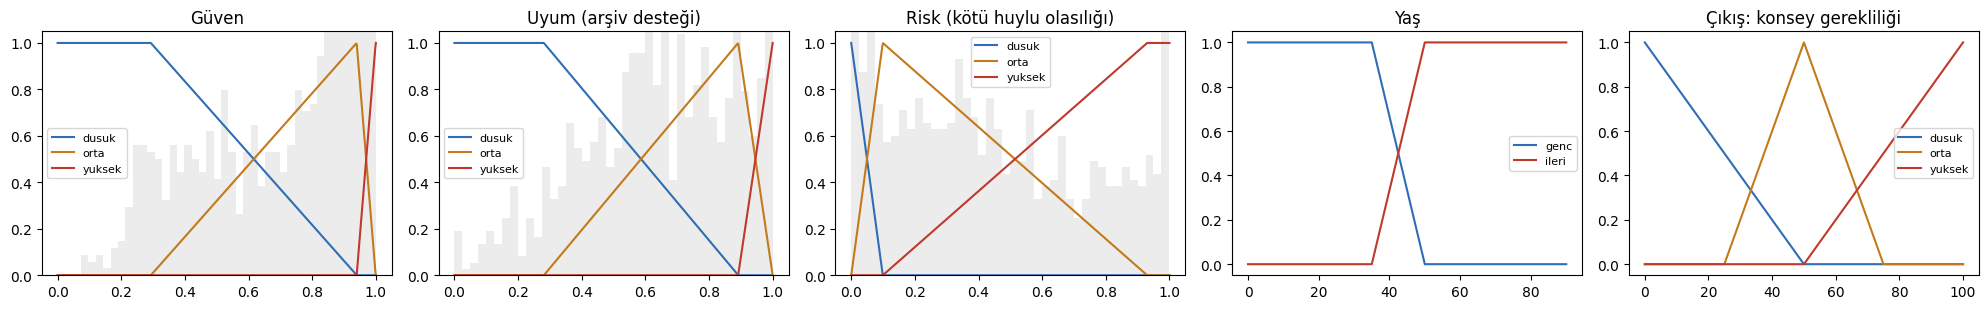

In [4]:
def girdiler(k):
    n = len(KUME[k]); i = np.arange(n)
    return {'guven': P_CNN[k][i, KARAR[k]],
            'uyum': P_ARSIV[k][i, KARAR[k]],
            'risk': 0.5 * (P_CNN[k][:, KOTU_HUYLU].sum(1) + P_ARSIV[k][:, KOTU_HUYLU].sum(1)),
            'yas': KUME[k]['age'].astype(float).values}

GIRDI = {k: girdiler(k) for k in KUME}

def yuzdelik(x):
    q = np.quantile(x, [0.05, 0.5, 0.95])
    for j in (1, 2):                      # sınırlar eşit çıkarsa küçük bir pay bırak
        q[j] = max(q[j], q[j - 1] + 1e-4)
    return tuple(float(v) for v in q)

YUZDELIK = {g: yuzdelik(GIRDI['dogrulama'][g]) for g in ['guven', 'uyum', 'risk']}
KAPI = bk.BulanikKapi(YUZDELIK)

print('Doğrulama dağılımından alınan küme sınırları (%5 / %50 / %95):')
print(pd.DataFrame(YUZDELIK, index=['q05', 'q50', 'q95']).round(3).to_string())
print(f"\nYaşı bilinmeyen: doğrulama {np.isnan(GIRDI['dogrulama']['yas']).sum()}, test {np.isnan(GIRDI['test']['yas']).sum()}")

fig, eksen = plt.subplots(1, 5, figsize=(20, 3.2))
renk = {'dusuk': '#2F6DB5', 'orta': '#C27A1A', 'yuksek': '#C0392B', 'genc': '#2F6DB5', 'ileri': '#C0392B'}
ad = {'guven': 'Güven', 'uyum': 'Uyum (arşiv desteği)', 'risk': 'Risk (kötü huylu olasılığı)'}
for ax, g in zip(eksen[:3], ['guven', 'uyum', 'risk']):
    x = np.linspace(0, 1, 501)
    for kume, p in bk.uc_kume(*YUZDELIK[g]).items():
        ax.plot(x, bk.yamuk(x, *p), color=renk[kume], label=kume)
    ax.hist(GIRDI['dogrulama'][g], bins=40, density=True, alpha=0.15, color='gray')
    ax.set_ylim(0, 1.05); ax.set_title(ad[g]); ax.legend(fontsize=8)
x = np.linspace(0, 90, 361)
for kume, p in bk.YAS_KUMELERI.items():
    eksen[3].plot(x, bk.yamuk(x, *p), color=renk[kume], label=kume)
eksen[3].set_title('Yaş'); eksen[3].legend(fontsize=8)
for kume, p in bk.CIKIS_KUMELERI.items():
    eksen[4].plot(bk.CIKIS_EVRENI, bk.yamuk(bk.CIKIS_EVRENI, *p), color=renk[kume], label=kume)
eksen[4].set_title('Çıkış: konsey gerekliliği'); eksen[4].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_uyelik_fonksiyonlari.png', dpi=150); plt.show()

## 4. Kural tabanı
12 kural, bütün güven × uyum birleşimlerini kapsar (her vakada en az bir kural ateşlenir). Mantık:
- Güven ya da uyum **düşükse** konsey toplanır (K1, K2).
- İkisi de yüksekse konsey gerekmez; risk yüksekse yine de orta düzeyde önerilir (K3-K5).
- Biri ortaysa risk belirleyicidir (K6-K11).
- İleri yaşta yüksek riskli ve tam emin olunmayan vakada konsey toplanır (K12).

In [5]:
print(pd.DataFrame([(ad, metin) for ad, metin, _, _ in bk.KURALLAR], columns=['kural', 'metin']).to_string(index=False))

kural                                                                            metin
   K1                                                    güven DÜŞÜK ise konsey YÜKSEK
   K2                                                     uyum DÜŞÜK ise konsey YÜKSEK
   K3                       güven YÜKSEK ve uyum YÜKSEK ve risk DÜŞÜK ise konsey DÜŞÜK
   K4                        güven YÜKSEK ve uyum YÜKSEK ve risk ORTA ise konsey DÜŞÜK
   K5                       güven YÜKSEK ve uyum YÜKSEK ve risk YÜKSEK ise konsey ORTA
   K6                         güven ORTA ve uyum YÜKSEK ve risk DÜŞÜK ise konsey DÜŞÜK
   K7             güven ORTA ve uyum YÜKSEK ve risk (ORTA veya YÜKSEK) ise konsey ORTA
   K8                         güven YÜKSEK ve uyum ORTA ve risk DÜŞÜK ise konsey DÜŞÜK
   K9             güven YÜKSEK ve uyum ORTA ve risk (ORTA veya YÜKSEK) ise konsey ORTA
  K10                            güven ORTA ve uyum ORTA ve risk DÜŞÜK ise konsey ORTA
  K11             güven ORTA ve uyum ORTA v

### Bağımsız kontrol: scikit-fuzzy ile aynı sonuç mu?
Kendi vektörel çıkarım kodumuz, aynı kümeler ve kurallarla kurulan `scikit-fuzzy` kontrol sistemiyle rastgele 30 vakada karşılaştırılır. İki yöntemin ayrıklaştırma ayrıntıları farklı olduğundan 0-100 ölçeğinde 1 puandan küçük farklar normaldir.

In [6]:
try:
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl
    evren = np.linspace(0, 1, 1001)
    A = {g: ctrl.Antecedent(evren, g) for g in ['guven', 'uyum', 'risk']}
    for g, a in A.items():
        for kume, p in bk.uc_kume(*YUZDELIK[g]).items():
            a[kume] = fuzz.trapmf(evren, list(p))
    A['yas'] = ctrl.Antecedent(np.linspace(0, 150, 1501), 'yas')
    for kume, p in bk.YAS_KUMELERI.items():
        A['yas'][kume] = fuzz.trapmf(A['yas'].universe, list(p))
    C = ctrl.Consequent(bk.CIKIS_EVRENI, 'konsey', defuzzify_method='centroid')
    for kume, p in bk.CIKIS_KUMELERI.items():
        C[kume] = fuzz.trapmf(bk.CIKIS_EVRENI, list(p))
    g, u, r, y = A['guven'], A['uyum'], A['risk'], A['yas']
    sk_kurallar = [ctrl.Rule(g['dusuk'], C['yuksek']), ctrl.Rule(u['dusuk'], C['yuksek']),
                   ctrl.Rule(g['yuksek'] & u['yuksek'] & r['dusuk'], C['dusuk']),
                   ctrl.Rule(g['yuksek'] & u['yuksek'] & r['orta'], C['dusuk']),
                   ctrl.Rule(g['yuksek'] & u['yuksek'] & r['yuksek'], C['orta']),
                   ctrl.Rule(g['orta'] & u['yuksek'] & r['dusuk'], C['dusuk']),
                   ctrl.Rule(g['orta'] & u['yuksek'] & (r['orta'] | r['yuksek']), C['orta']),
                   ctrl.Rule(g['yuksek'] & u['orta'] & r['dusuk'], C['dusuk']),
                   ctrl.Rule(g['yuksek'] & u['orta'] & (r['orta'] | r['yuksek']), C['orta']),
                   ctrl.Rule(g['orta'] & u['orta'] & r['dusuk'], C['orta']),
                   ctrl.Rule(g['orta'] & u['orta'] & (r['orta'] | r['yuksek']), C['yuksek']),
                   ctrl.Rule(y['ileri'] & r['yuksek'] & ~(g['yuksek'] & u['yuksek']), C['yuksek'])]
    sim = ctrl.ControlSystemSimulation(ctrl.ControlSystem(sk_kurallar))
    G = GIRDI['dogrulama']
    bilinen = np.where(~np.isnan(G['yas']))[0]
    ornek = rng.choice(bilinen, size=min(30, len(bilinen)), replace=False)
    farklar = []
    for i in ornek:
        for ad_ in ['guven', 'uyum', 'risk', 'yas']:
            sim.input[ad_] = float(G[ad_][i])
        sim.compute()
        farklar.append(abs(sim.output['konsey'] - KAPI.skor(G['guven'][i], G['uyum'][i], G['risk'][i], G['yas'][i])[0]))
    print(f'scikit-fuzzy ile en büyük fark: {max(farklar):.3f} puan (ortalama {np.mean(farklar):.3f}) '
          f'-> {"AYNI SONUÇ" if max(farklar) < 1.0 else "DİKKAT: fark büyük, bana haber ver"}')
except Exception as hata:
    print('scikit-fuzzy karşılaştırması yapılamadı (sonuçları etkilemez):', repr(hata))

scikit-fuzzy ile en büyük fark: 0.247 puan (ortalama 0.158) -> AYNI SONUÇ


## 5. Konsey puanları ve eşik
Her vaka için puan hesaplanır. Eşik, **doğrulama** puanlarının %80. yüzdeliğidir (doğrulamada vakaların %20'si konseye gider). Test için aynı eşik kullanılır; testte konseye giden oran biraz farklı çıkabilir.

dogrulama: puan ortanca 67.8 | eşik 83.11 üstü (konseye giden) %20.0 | tavan puanda (sıralanamayan) %9.8
test     : puan ortanca 72.4 | eşik 83.11 üstü (konseye giden) %23.6 | tavan puanda (sıralanamayan) %12.1


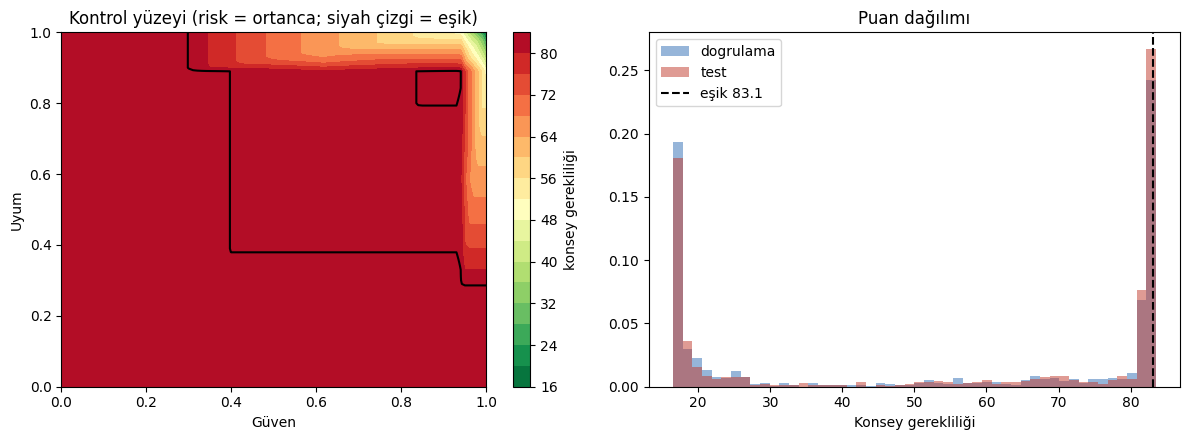

In [7]:
SKOR = {k: KAPI.skor(**GIRDI[k]) for k in KUME}
ESIK = float(np.quantile(SKOR['dogrulama'], 1 - KONSEY_BUTCESI))
TAVAN = bk.BulanikKapi(YUZDELIK).skor(0.0, 0.0, 1.0, 80.0)[0]   # mümkün olan en yüksek puan
for k in KUME:
    print(f'{k:9s}: puan ortanca {np.median(SKOR[k]):.1f} | eşik {ESIK:.2f} üstü (konseye giden) %{100 * (SKOR[k] > ESIK).mean():.1f} | '
          f'tavan puanda (sıralanamayan) %{100 * np.isclose(SKOR[k], TAVAN).mean():.1f}')
assert ESIK < TAVAN - 1e-6, 'Eşik tavan puana denk geldi: konsey bütçesi tavandaki vakalardan küçük. Bana haber ver.'

# Kontrol yüzeyi: risk ortanca değerinde, yaş bilinmiyorken güven × uyum
gg, uu = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 1, 101))
yuzey = KAPI.skor(gg.ravel(), uu.ravel(), np.full(gg.size, YUZDELIK['risk'][1]), np.full(gg.size, np.nan)).reshape(gg.shape)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
im = ax[0].contourf(gg, uu, yuzey, levels=20, cmap='RdYlGn_r'); plt.colorbar(im, ax=ax[0], label='konsey gerekliliği')
ax[0].contour(gg, uu, yuzey, levels=[ESIK], colors='black', linewidths=1.5)
ax[0].set_xlabel('Güven'); ax[0].set_ylabel('Uyum'); ax[0].set_title('Kontrol yüzeyi (risk = ortanca; siyah çizgi = eşik)')
for k, renk_ in [('dogrulama', '#2F6DB5'), ('test', '#C0392B')]:
    ax[1].hist(SKOR[k], bins=50, alpha=0.5, density=True, label=k, color=renk_)
ax[1].axvline(ESIK, color='black', linestyle='--', label=f'eşik {ESIK:.1f}'); ax[1].legend()
ax[1].set_xlabel('Konsey gerekliliği'); ax[1].set_title('Puan dağılımı')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_kontrol_yuzeyi.png', dpi=150); plt.show()

## 6. Karşılaştırma: bulanık kapı ve temel çizgiler
Her yöntem vakaları bir öncelik puanına göre sıralar ve aynı sayıda vakayı uzmana gönderir:
- **Yalnız güven** (Adım 3): en az emin olunan vakalar.
- **Güven + uyumsuzluk** (Adım 4): önce CNN ile arşivin farklı tanı söylediği vakalar, kalan kontenjan güvene göre.
- **Bulanık kapı:** konsey gerekliliği puanı en yüksek olanlar.

**Ablasyon (hangi girdi ne katıyor?):**
- *Bulanık, arşivsiz:* uyum girdisi sabit "yüksek" verilir; arşiv bilgisi kullanılmaz.
- *Bulanık, yaş kuralsız:* K12 çıkarılır.

Ölçütler, sistemin **kendisinin karar verdiği** vakalarda hesaplanır. Konseye giden vakalar henüz değerlendirilmiyor; o iş ajanların olacak.

In [8]:
KAPI_ARSIVSIZ = bk.BulanikKapi(YUZDELIK)
KAPI_YASSIZ = bk.BulanikKapi(YUZDELIK, kurallar=[k[0] for k in bk.KURALLAR if k[0] != 'K12'])

def oncelikler(k):
    G = GIRDI[k]; uyumsuz = KARAR[k] != P_ARSIV[k].argmax(1)
    return {'yalnız güven': -G['guven'],
            'güven + uyumsuzluk': -G['guven'] + 10.0 * uyumsuz,
            'bulanık kapı': SKOR[k],
            'bulanık, arşivsiz': KAPI_ARSIVSIZ.skor(G['guven'], np.ones_like(G['uyum']), G['risk'], G['yas']),
            'bulanık, yaş kuralsız': KAPI_YASSIZ.skor(**G)}

def sec(oncelik, n_konsey):
    konsey = np.zeros(len(oncelik), bool)
    konsey[np.argsort(-oncelik, kind='stable')[:n_konsey]] = True
    return konsey

def olc(k, konsey, ix=None):
    ix = np.arange(len(Y[k])) if ix is None else ix
    y, t, kv = Y[k][ix], KARAR[k][ix], konsey[ix]
    karar_ver = ~kv
    return {'konsey_orani': kv.mean(),
            'dogruluk': (t[karar_ver] == y[karar_ver]).mean(),
            'dengeli_dogruluk': balanced_accuracy_score(y[karar_ver], t[karar_ver]),
            'kacirilan_melanom': int(((y == MEL) & karar_ver & (t != MEL)).sum()),
            'yanlis_alarm_nevus': int(((y == NV) & karar_ver & (t == MEL)).sum())}

ONCELIK = {k: oncelikler(k) for k in KUME}
N_KONSEY = {k: int((SKOR[k] > ESIK).sum()) for k in KUME}   # bulanık eşiğin gönderdiği sayı; herkes aynı sayıyı gönderir
TABLO = {}
for k in KUME:
    TABLO[k] = pd.DataFrame({ad: olc(k, sec(o, N_KONSEY[k])) for ad, o in ONCELIK[k].items()}).T
    print(f'\n=== {k.upper()}: {N_KONSEY[k]} vaka (%{100 * N_KONSEY[k] / len(Y[k]):.1f}) konseye gidiyor ===')
    print(TABLO[k].round(3).to_string())
    print(f'Hiç konsey olmasaydı: dengeli doğruluk {balanced_accuracy_score(Y[k], KARAR[k]):.3f}, '
          f'kaçırılan melanom {int(((Y[k] == MEL) & (KARAR[k] != MEL)).sum())}, yanlış alarm {int(((Y[k] == NV) & (KARAR[k] == MEL)).sum())}')


=== DOGRULAMA: 293 vaka (%20.0) konseye gidiyor ===
                       konsey_orani  dogruluk  dengeli_dogruluk  kacirilan_melanom  yanlis_alarm_nevus
yalnız güven                    0.2     0.914             0.815               15.0                26.0
güven + uyumsuzluk              0.2     0.892             0.850               13.0                45.0
bulanık kapı                    0.2     0.880             0.822               16.0                50.0
bulanık, arşivsiz               0.2     0.910             0.810               18.0                26.0
bulanık, yaş kuralsız           0.2     0.887             0.847               14.0                47.0
Hiç konsey olmasaydı: dengeli doğruluk 0.763, kaçırılan melanom 29, yanlış alarm 131

=== TEST: 353 vaka (%23.6) konseye gidiyor ===
                       konsey_orani  dogruluk  dengeli_dogruluk  kacirilan_melanom  yanlis_alarm_nevus
yalnız güven                  0.236     0.890             0.778               16.0           

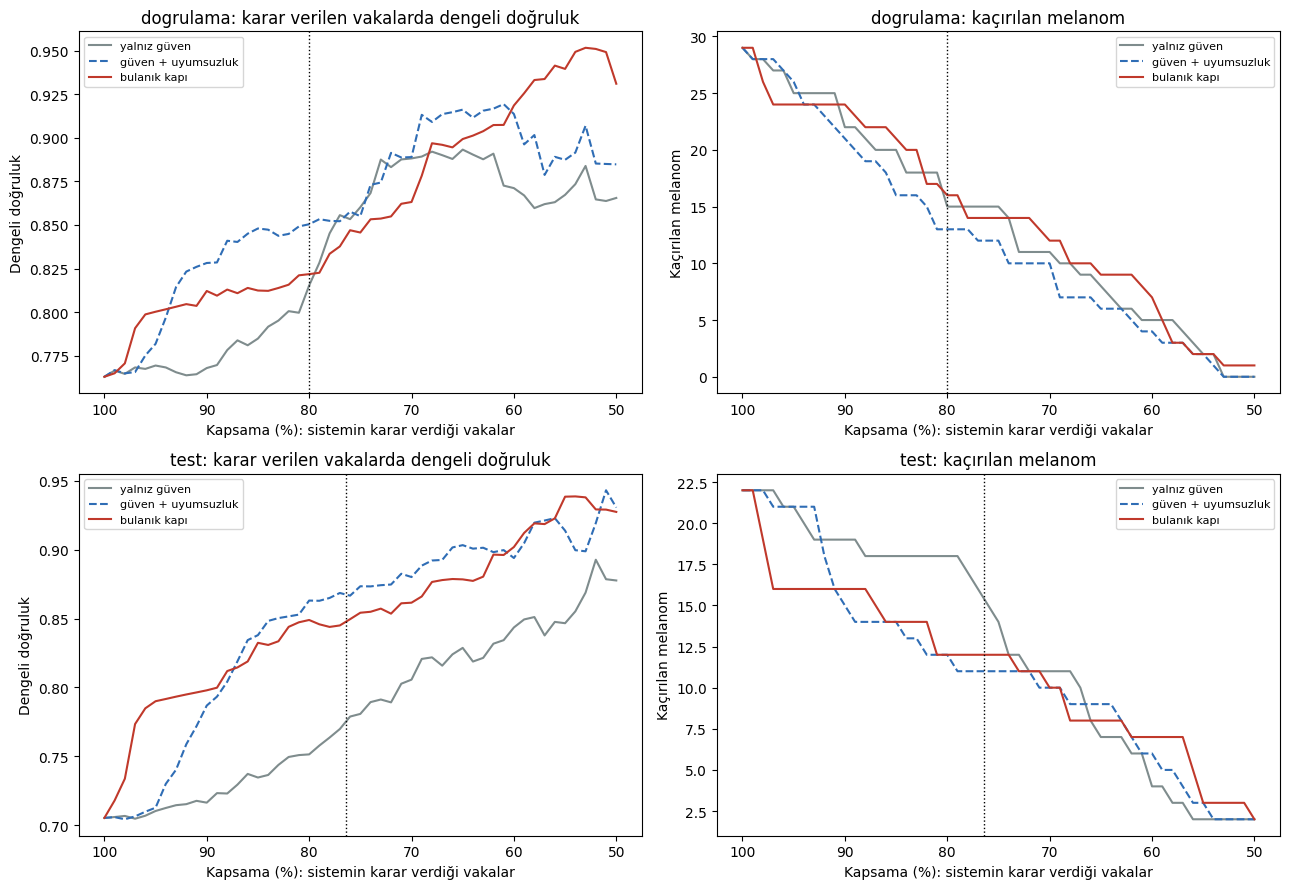

In [9]:
kapsamalar = np.round(np.arange(1.0, 0.495, -0.01), 2)
fig, eksen = plt.subplots(2, 2, figsize=(13, 9))
cizgi = {'yalnız güven': ('#7F8C8D', '-'), 'güven + uyumsuzluk': ('#2F6DB5', '--'), 'bulanık kapı': ('#C0392B', '-')}
for r, k in enumerate(['dogrulama', 'test']):
    for ad, (renk_, stil) in cizgi.items():
        d = pd.DataFrame([olc(k, sec(ONCELIK[k][ad], len(Y[k]) - int(round(c * len(Y[k]))))) for c in kapsamalar])
        eksen[r, 0].plot(kapsamalar * 100, d['dengeli_dogruluk'], stil, color=renk_, label=ad)
        eksen[r, 1].plot(kapsamalar * 100, d['kacirilan_melanom'], stil, color=renk_, label=ad)
    for c in (0, 1):
        eksen[r, c].axvline(100 * (1 - N_KONSEY[k] / len(Y[k])), color='black', linestyle=':', linewidth=1)
        eksen[r, c].invert_xaxis(); eksen[r, c].set_xlabel('Kapsama (%): sistemin karar verdiği vakalar'); eksen[r, c].legend(fontsize=8)
    eksen[r, 0].set_ylabel('Dengeli doğruluk'); eksen[r, 0].set_title(f'{k}: karar verilen vakalarda dengeli doğruluk')
    eksen[r, 1].set_ylabel('Kaçırılan melanom'); eksen[r, 1].set_title(f'{k}: kaçırılan melanom')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_karsilastirma_egrileri.png', dpi=150); plt.show()

## 7. Fark gerçek mi? (eşleştirilmiş, lezyon bazlı bootstrap)
Test kümesinde bulanık kapı ile iki temel çizginin farkı için %95 güven aralıkları. Vakaların yönlendirmesi sabit tutulur, test kümesi lezyon bazında 1.000 kez yeniden örneklenir. Aralık 0'ı içermiyorsa fark belirgin sayılır.

In [10]:
gruplar = [np.array(ix) for ix in KUME['test'].groupby('lesion_id').indices.values()]
ORNEKLER = [np.concatenate([gruplar[i] for i in rng.integers(0, len(gruplar), len(gruplar))]) for _ in range(1000)]
KONSEY_TEST = {ad: sec(o, N_KONSEY['test']) for ad, o in ONCELIK['test'].items()}

FARKLAR = {}
for rakip in ['yalnız güven', 'güven + uyumsuzluk']:
    for olcut in ['dengeli_dogruluk', 'dogruluk', 'kacirilan_melanom']:
        f = lambda ix: olc('test', KONSEY_TEST['bulanık kapı'], ix)[olcut] - olc('test', KONSEY_TEST[rakip], ix)[olcut]
        d = [f(ix) for ix in ORNEKLER]
        FARKLAR[(rakip, olcut)] = (float(f(np.arange(len(Y['test'])))), *map(float, np.percentile(d, [2.5, 97.5])))
print('Bulanık kapı − rakip (test; kaçırılan melanomda eksi = daha iyi)\n')
for (rakip, olcut), (d, a, u) in FARKLAR.items():
    print(f'{rakip:20s} {olcut:18s}: {d:+.3f}  [%95: {a:+.3f}, {u:+.3f}]  -> {"belirgin" if a > 0 or u < 0 else "belirgin değil"}')

Bulanık kapı − rakip (test; kaçırılan melanomda eksi = daha iyi)

yalnız güven         dengeli_dogruluk  : +0.070  [%95: +0.021, +0.124]  -> belirgin
yalnız güven         dogruluk          : -0.031  [%95: -0.049, -0.013]  -> belirgin
yalnız güven         kacirilan_melanom : -4.000  [%95: -9.000, +0.000]  -> belirgin değil
güven + uyumsuzluk   dengeli_dogruluk  : -0.019  [%95: -0.061, +0.019]  -> belirgin değil
güven + uyumsuzluk   dogruluk          : -0.014  [%95: -0.025, -0.004]  -> belirgin
güven + uyumsuzluk   kacirilan_melanom : +1.000  [%95: +0.000, +3.000]  -> belirgin değil


## 8. Konseye kimler gidiyor?
Konseyin (ileride ajanların) karşılaşacağı vakalar: CNN'in hatalarının ne kadarı burada? Kaçan melanomların ve yanlış alarmların ne kadarı yakalanıyor?

In [11]:
def icerik(k, konsey):
    y, t = Y[k], KARAR[k]; hata = t != y
    return {'konseye_giden': int(konsey.sum()),
            'konseydekilerde_CNN_dogrulugu': (t[konsey] == y[konsey]).mean(),
            'CNN_hatalarinin_yakalanan_payi': (hata & konsey).sum() / max(hata.sum(), 1),
            'kacan_melanomlarin_yakalanan_payi': ((y == MEL) & (t != MEL) & konsey).sum() / max(((y == MEL) & (t != MEL)).sum(), 1),
            'yanlis_alarmlarin_yakalanan_payi': ((y == NV) & (t == MEL) & konsey).sum() / max(((y == NV) & (t == MEL)).sum(), 1),
            'konseydeki_patoloji_dogrulamali_payi': (KUME[k]['dx_type'].values[konsey] == 'histo').mean()}
ICERIK = {f'{ad} ({k})': icerik(k, sec(ONCELIK[k][ad], N_KONSEY[k])) for k in KUME for ad in ['yalnız güven', 'bulanık kapı']}
print(pd.DataFrame(ICERIK).round(3).to_string())

# Hangi kurallar konsey kararlarını taşıyor?
s, m, guc = KAPI.skor(**GIRDI['test'], ayrinti=True)
kv = s > ESIK
print('\nTest: konseye giden vakalarda kuralların ortalama ateşlenme gücü')
print(pd.Series({ad: float(guc[ad][kv].mean()) for ad, *_ in bk.KURALLAR}).sort_values(ascending=False).round(3).to_string())

                                      yalnız güven (dogrulama)  bulanık kapı (dogrulama)  yalnız güven (test)  bulanık kapı (test)
konseye_giden                                          293.000                   293.000              353.000              353.000
konseydekilerde_CNN_dogrulugu                            0.334                     0.468                0.261                0.360
CNN_hatalarinin_yakalanan_payi                           0.659                     0.527                0.674                0.584
kacan_melanomlarin_yakalanan_payi                        0.483                     0.448                0.273                0.455
yanlis_alarmlarin_yakalanan_payi                         0.802                     0.618                0.834                0.627
konseydeki_patoloji_dogrulamali_payi                     0.887                     0.891                0.864                0.847

Test: konseye giden vakalarda kuralların ortalama ateşlenme gücü
K1     0.693
K2  

## 9. Açıklanabilirlik: tek vakada kapının gerekçesi
Hakem ajanın raporuna girecek gerekçe bu biçimde olacak: girdiler, dilsel değerleri ve ateşlenen kurallar.

In [12]:
ETIKET_TR = {'dusuk': 'düşük', 'orta': 'orta', 'yuksek': 'yüksek', 'genc': 'genç', 'ileri': 'ileri'}
def acikla(k, i):
    G = {g: GIRDI[k][g][i] for g in GIRDI[k]}
    s, m, guc = KAPI.skor(*[G[g] for g in ['guven', 'uyum', 'risk', 'yas']], ayrinti=True)
    print(f'--- {KUME[k].loc[i, "image_id"]} | gerçek: {KUME[k].loc[i, "dx"]} | CNN: {SINIFLAR[KARAR[k][i]]} | '
          f'arşiv: {SINIFLAR[P_ARSIV[k][i].argmax()]} | yaş: {G["yas"]}')
    for g in ['guven', 'uyum', 'risk', 'yas']:
        uy = {ETIKET_TR[kk]: round(float(v[0]), 2) for kk, v in m[g].items() if v[0] > 0}
        print(f'  {g:6s} = {G[g]:.3f}  ->  {uy}')
    for ad, metin, _, _ in bk.KURALLAR:
        if guc[ad][0] > 0.05:
            print(f'  {ad:4s} (güç {guc[ad][0]:.2f}): {metin}')
    print(f'  KONSEY GEREKLİLİĞİ = {s[0]:.1f} (eşik {ESIK:.1f}) -> {"KONSEY TOPLANSIN" if s[0] > ESIK else "CNN kararı tanı önerisi olarak verilir"}\n')

y_t, t_t = Y['test'], KARAR['test']
secimler = {'kaçan melanom': np.where((y_t == MEL) & (t_t != MEL))[0],
            'yanlış alarm': np.where((y_t == NV) & (t_t == MEL))[0],
            'konseye gitmeyen doğru karar': np.where((t_t == y_t) & (SKOR['test'] < ESIK))[0]}
for ad, ix in secimler.items():
    if len(ix):
        print(f'### {ad}'); acikla('test', int(rng.choice(ix)))

### kaçan melanom
--- ISIC_0033027 | gerçek: mel | CNN: nv | arşiv: bcc | yaş: 70.0
  guven  = 0.659  ->  {'düşük': 0.43, 'orta': 0.57}
  uyum   = 0.288  ->  {'düşük': 0.99, 'orta': 0.01}
  risk   = 0.371  ->  {'orta': 0.67, 'yüksek': 0.33}
  yas    = 70.000  ->  {'ileri': 1.0}
  K1   (güç 0.43): güven DÜŞÜK ise konsey YÜKSEK
  K2   (güç 0.99): uyum DÜŞÜK ise konsey YÜKSEK
  K12  (güç 0.33): yaş İLERİ ve risk YÜKSEK ve DEĞİL(güven YÜKSEK ve uyum YÜKSEK) ise konsey YÜKSEK
  KONSEY GEREKLİLİĞİ = 83.5 (eşik 83.1) -> KONSEY TOPLANSIN

### yanlış alarm
--- ISIC_0026400 | gerçek: nv | CNN: mel | arşiv: nv | yaş: 75.0
  guven  = 0.239  ->  {'düşük': 1.0}
  uyum   = 0.402  ->  {'düşük': 0.8, 'orta': 0.2}
  risk   = 0.322  ->  {'orta': 0.73, 'yüksek': 0.27}
  yas    = 75.000  ->  {'ileri': 1.0}
  K1   (güç 1.00): güven DÜŞÜK ise konsey YÜKSEK
  K2   (güç 0.80): uyum DÜŞÜK ise konsey YÜKSEK
  K12  (güç 0.27): yaş İLERİ ve risk YÜKSEK ve DEĞİL(güven YÜKSEK ve uyum YÜKSEK) ise konsey YÜKSEK
  KONS

## 10. Kaydet

In [13]:
ayarlar = {'yuzdelikler': YUZDELIK, 'yas_kumeleri': bk.YAS_KUMELERI, 'cikis_kumeleri': bk.CIKIS_KUMELERI,
           'kurallar': [(ad, metin, c) for ad, metin, _, c in bk.KURALLAR], 'esik': ESIK, 'konsey_butcesi': KONSEY_BUTCESI,
           'girdi_tanimlari': {'guven': 'kalibre CNN olasılığı, CNN klinik kararı için',
                               'uyum': 'arşiv olasılığı, CNN klinik kararı için',
                               'risk': '0,5 × (CNN + arşiv) kötü huylu (mel+bcc+akiec) olasılığı',
                               'yas': 'hasta yaşı; bilinmiyorsa genç ve ileri üyeliği 0,5'},
           'cikarim': 'Mamdani; VE=min, VEYA=max, DEĞİL=1-µ; max birleştirme; ağırlık merkezi'}
with open(f'{PROJE}/bulanik/05_kapi_ayarlari.json', 'w', encoding='utf-8') as f:
    json.dump(ayarlar, f, ensure_ascii=False, indent=2)
for k in KUME:
    np.save(f'{PROJE}/bulanik/kapi_skoru_{k}.npy', SKOR[k])
with open(f'{PROJE}/results/{ON}_bulanik_kapi_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump({'ayarlar': ayarlar, 'n_konsey': N_KONSEY,
               'karsilastirma': {k: v.reset_index().rename(columns={'index': 'yontem'}).to_dict(orient='records') for k, v in TABLO.items()},
               'bootstrap_farklar': {f'{a} | {b}': v for (a, b), v in FARKLAR.items()},
               'konsey_icerigi': {a: {b: float(c) for b, c in d.items()} for a, d in ICERIK.items()}},
              f, ensure_ascii=False, indent=2, default=float)
print('Kaydedildi:')
for p in ['src/bulanik_kapi.py', 'bulanik/05_kapi_ayarlari.json', 'bulanik/kapi_skoru_dogrulama.npy', 'bulanik/kapi_skoru_test.npy',
          f'results/{ON}_bulanik_kapi_sonuclari.json', f'results/{ON}_uyelik_fonksiyonlari.png',
          f'results/{ON}_kontrol_yuzeyi.png', f'results/{ON}_karsilastirma_egrileri.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  src/bulanik_kapi.py ✓
  bulanik/05_kapi_ayarlari.json ✓
  bulanik/kapi_skoru_dogrulama.npy ✓
  bulanik/kapi_skoru_test.npy ✓
  results/05_bulanik_kapi_sonuclari.json ✓
  results/05_uyelik_fonksiyonlari.png ✓
  results/05_kontrol_yuzeyi.png ✓
  results/05_karsilastirma_egrileri.png ✓


## Bu adımın sonunda
- Bulanık kapı hazır: `src/bulanik_kapi.py` (kod) ve `bulanik/05_kapi_ayarlari.json` (dondurulmuş ayarlar).
- "Asgari" sürüm tamamlandı: **CNN + benzer vaka arşivi + bulanık mantık kapısı**.
- **Bana gönder:** defteri *Dosya → İndir → .ipynb* ile indirip gönder.